ROOT NODE: GAIN RATIO
Entropy: 0.9604
Attribute         Gain   SplitInfo   GainRatio   Threshold
Pclass          0.0877      1.4425      0.0608           -
Sex             0.2227      0.9387      0.2372           -
Embarked        0.0253      1.0794      0.0234           -
Age             0.0117      0.0702      0.1673        0.96
SibSp           0.0079      0.0889      0.0888         4.5
Parch           0.0010      0.0153      0.0640         5.5
Fare            0.0039      0.0279      0.1398      387.66

Best root: Sex | Gain Ratio: 0.2372


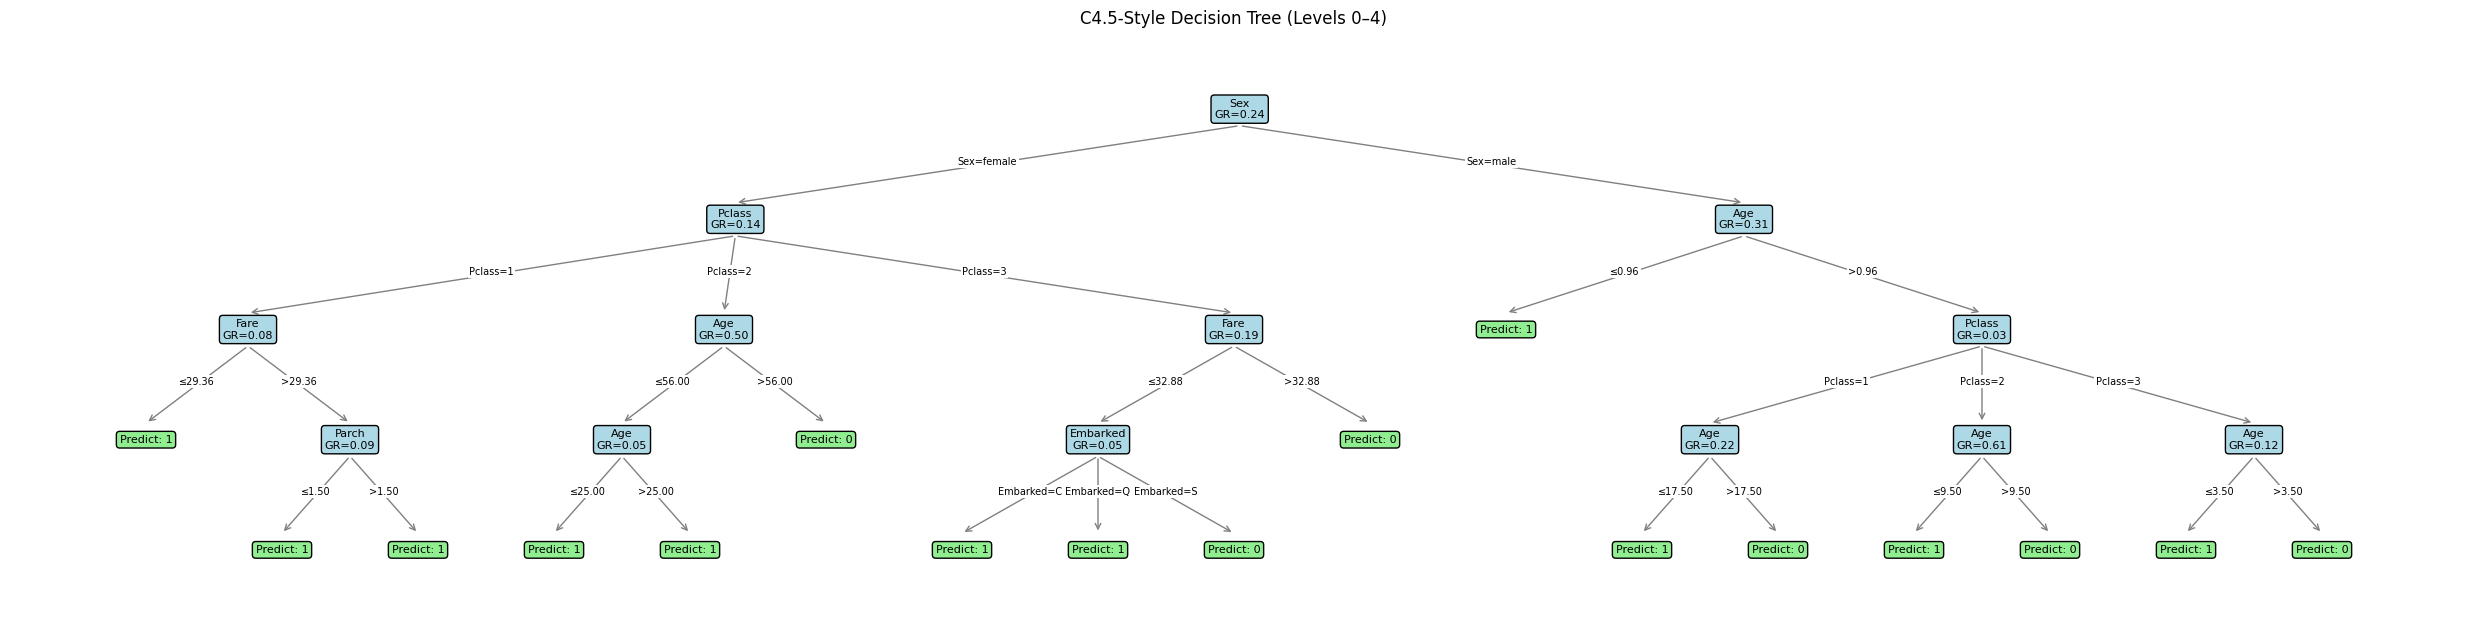


MODEL EVALUATION
Accuracy  : 0.7877
Precision : 0.8163
Recall    : 0.5797
F1 Score  : 0.6780

Confusion Matrix:
 [[101   9]
 [ 29  40]]


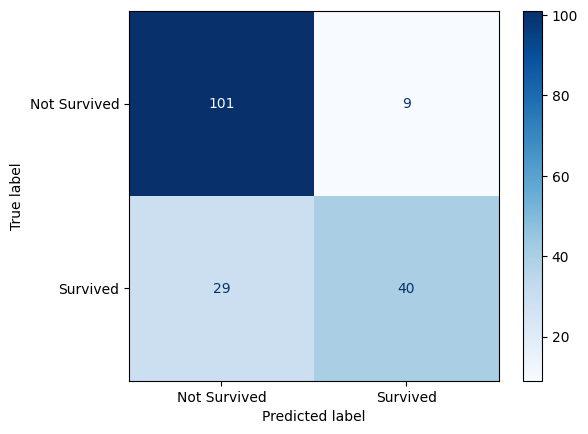

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay)

#Load and preprocess
url = "https://drive.google.com/uc?export=download&id=1AlP4b9I55Tu7jYkV7clxJf8nvLMOvmnp"
cols = ["Survived","Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"]
df = pd.read_csv(url)[cols].copy()

for c in ["Survived","Pclass","Age","SibSp","Parch","Fare"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna(subset=["Survived"])
df[["Age","Fare"]] = df[["Age","Fare"]].fillna(df[["Age","Fare"]].median())
for c in ["Sex","Embarked"]:
    df[c] = df[c].fillna(df[c].mode()[0])
df = df.dropna().reset_index(drop=True)
df["Pclass"] = df["Pclass"].astype(int).astype(str)

T = "Survived"
CAT = ["Pclass","Sex","Embarked"]
FEATURES = CAT + ["Age","SibSp","Parch","Fare"]

train, test = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df[T])
train, test = train.reset_index(drop=True), test.reset_index(drop=True)

#Entropy and Gain Ratio
def entropy(y):
    p = y.value_counts(normalize=True).to_numpy()
    return -np.sum(p * np.log2(p))

def gain_ratio(parent, parts, n):
    si = -sum(len(p)/n*np.log2(len(p)/n) for p in parts if len(p))
    gain = parent - sum(len(p)/n*entropy(p) for p in parts if len(p))
    return gain, si, gain/si if si else 0

def evaluate(d, f):
    h, n = entropy(d[T]), len(d)
    if f in CAT:
        return (*gain_ratio(h, [g[T] for _,g in d.groupby(f)], n), None)
    v = np.sort(d[f].unique())
    best = (0, 0, 0, None)
    for a, b in zip(v[:-1], v[1:]):
        th = (a+b)/2
        parts = [d.loc[d[f]<=th,T], d.loc[d[f]>th,T]]
        g, si, gr = gain_ratio(h, parts, n)
        if gr > best[2]:
            best = (g, si, gr, th)
    return best

#Build C4.5 style tree
def build_tree(d, features, depth=0, max_depth=4, min_samples=20):
    y = d[T]
    majority = y.mode().iloc[0]
    if y.nunique()==1 or depth>=max_depth or len(d)<min_samples or not features:
        return {"leaf": majority}

    results = {f:evaluate(d,f) for f in features}
    avg = np.mean([r[0] for r in results.values()])
    candidates = {f:r for f,r in results.items() if r[0]>=avg-1e-12}
    if not candidates:
        return {"leaf": majority}

    best = max(candidates, key=lambda f:candidates[f][2])
    gain, si, gr, th = results[best]
    if gr <= 0:
        return {"leaf": majority}

    if depth == 0:
        print("ROOT NODE: GAIN RATIO")
        print("Entropy:", round(entropy(y),4))
        print(f"{'Attribute':<12}{'Gain':>10}{'SplitInfo':>12}"
              f"{'GainRatio':>12}{'Threshold':>12}")
        for f,(g,s,r,t) in results.items():
            print(f"{f:<12}{g:>10.4f}{s:>12.4f}{r:>12.4f}"
                  f"{str(round(t,2) if t is not None else '-'):>12}")
        print(f"\nBest root: {best} | Gain Ratio: {gr:.4f}")

    node = {"attr":best, "threshold":th, "gain_ratio":gr, "children":{}}
    groups = (d.groupby(best, sort=True) if th is None else
              [("<=",d[d[best]<=th]),(">",d[d[best]>th])])

    for k, group in groups:
        key = str(k) if th is None else k
        fs = [f for f in features if f!=best] if th is None else features
        node["children"][key] = build_tree(group, fs, depth+1, max_depth, min_samples)
    return node

tree = build_tree(train, FEATURES)

#Plot Decision Tree
def plot_tree(root, max_level=3):
    nodes, edges, xleaf = {}, [], [0]

    def layout(n, depth=0, parent=None, branch=""):
        i = len(nodes)
        leaf = "leaf" in n
        cut = not leaf and depth >= max_level
        label = (f"Predict: {n['leaf']}" if leaf else "..." if cut else
                 f"{n['attr']}\nGR={n['gain_ratio']:.2f}")
        nodes[i] = (label, depth, leaf, cut, 0)
        if parent is not None:
            edges.append((parent, i, branch))

        if leaf or cut:
            x = xleaf[0]
            xleaf[0] += 1
        else:
            xs = []
            for k, child in n["children"].items():
                b = (f"{n['attr']}={k}" if n["threshold"] is None else
                     f"{'≤' if k=='<=' else '>'}{n['threshold']:.2f}")
                xs.append(layout(child, depth+1, i, b))
            x = np.mean(xs)
        nodes[i] = (*nodes[i][:4], x)
        return x

    layout(root)
    width = max(12, xleaf[0]*1.5)
    fig, ax = plt.subplots(figsize=(width, 7))

    for p, c, label in edges:
        a, b = nodes[p], nodes[c]
        ax.annotate("", (b[4],-b[1]+.15), (a[4],-a[1]-.15),
                    arrowprops=dict(arrowstyle="->",color="gray"))
        ax.text((a[4]+b[4])/2, -(a[1]+b[1])/2, label,
                ha="center", fontsize=7,
                bbox=dict(facecolor="white",edgecolor="none",pad=1))

    for label, depth, leaf, cut, x in nodes.values():
        color = "lightgreen" if leaf else "lightyellow" if cut else "lightblue"
        ax.text(x,-depth,label,ha="center",va="center",fontsize=8,
                bbox=dict(boxstyle="round",facecolor=color,edgecolor="black"))

    ax.set_title(f"C4.5-Style Decision Tree (Levels 0–{max_level})")
    ax.set_ylim(-max_level-.7,.7)
    ax.set_xlim(-1,xleaf[0])
    ax.axis("off")
    fig.subplots_adjust(left=.02,right=.98,top=.90,bottom=.05)
    plt.show()

plot_tree(tree, 4)

#Prediction
def predict(node, row):
    while "leaf" not in node:
        f, th = node["attr"], node["threshold"]
        key = str(row[f]) if th is None else ("<=" if row[f]<=th else ">")
        node = node["children"].get(key)
        if node is None:
            return 0
    return node["leaf"]

y_true = test[T].astype(int).to_numpy()
y_pred = np.array([predict(tree,r) for _,r in test.iterrows()])

#Evaluation
print("\nMODEL EVALUATION")
for name, fn in [("Accuracy",accuracy_score),("Precision",precision_score),
                 ("Recall",recall_score),("F1 Score",f1_score)]:
    print(f"{name:<10}: {fn(y_true,y_pred,**({'zero_division':0} if name!='Accuracy' else {})):.4f}")

cm = confusion_matrix(y_true,y_pred,labels=[0,1])
print("\nConfusion Matrix:\n",cm)
ConfusionMatrixDisplay(cm,display_labels=["Not Survived","Survived"]).plot(
    cmap="Blues",values_format="d")
plt.show()
